<a href="https://colab.research.google.com/github/minxuan0923/AML_Assignment/blob/mx/Set5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Import libraries

In [2]:
import pandas as pd
from scipy.io import arff
import requests
from io import StringIO

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, fbeta_score

import tensorflow as tf
from tensorflow.keras import datasets, layers, models, optimizers, losses
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt

## Load Dataset

In [3]:
URL = (
    "https://raw.githubusercontent.com/"
    "minxuan0923/AML_Assignment/main/data/"
    "UCI_Phishing_Training_Dataset.arff"
)

response = requests.get(URL, timeout=30)
response.raise_for_status()

data, meta = arff.loadarff(StringIO(response.text))

df = pd.DataFrame(data)

for col in df.select_dtypes([object]):
    df[col] = pd.to_numeric(df[col].str.decode('utf-8'))

X_data = df.drop(columns =['Result'])
y_data = df['Result']

## Spliting

In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_data, y_data, random_state = 42, test_size=0.3, stratify=y_data)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)


## Encoding

In [5]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)

# One-hot-encoding X values
X_train_encoded = encoder.fit_transform(X_train)
X_val_encoded = encoder.fit_transform(X_val)
X_test_encoded = encoder.transform(X_test)

# Convert y values - phishing to "1" and legitimate to "0"
y_train = y_train.replace({-1: 1, 1: 0})
y_val = y_val.replace({-1: 1, 1: 0})
y_test = y_test.replace({-1: 1, 1: 0})

## Autoencoder

In [6]:
class Autoencoder(Model):
  def __init__(self, latent_dim, shape):
    super(Autoencoder, self).__init__()
    self.latent_dim = latent_dim
    self.shape = shape
    self.encoder = tf.keras.Sequential([
      layers.Flatten(),
      layers.Dense(latent_dim, activation='relu'),
    ])
    self.decoder = tf.keras.Sequential([
      layers.Dense(int(tf.math.reduce_prod(shape)), activation='sigmoid'),
      layers.Reshape(shape)
    ])

  def call(self, x):
    encoded = self.encoder(x)
    decoded = self.decoder(encoded)
    return decoded

In [108]:



shape = X_test_encoded.shape[1:]
latent_dim = 32 # we will experiment with 16 & 32
autoencoder = Autoencoder(latent_dim, shape)

autoencoder.compile(optimizer='adam', loss=losses.binary_crossentropy)

history_ae = autoencoder.fit(X_train_encoded, X_train_encoded,
                epochs=100,
                shuffle=True,
                validation_data=(X_val_encoded, X_val_encoded))

X_train_compressed = autoencoder.encoder.predict(X_train_encoded)
X_val_compressed = autoencoder.encoder.predict(X_val_encoded)
X_test_compressed = autoencoder.encoder.predict(X_test_encoded)

Epoch 1/100
242/242 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.4047 - val_loss: 0.2594
Epoch 2/100
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1999 - val_loss: 0.1516
Epoch 3/100
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1197 - val_loss: 0.0931
Epoch 4/100
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0751 - val_loss: 0.0606
Epoch 5/100
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0501 - val_loss: 0.0421
Epoch 6/100
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0355 - val_loss: 0.0310
Epoch 7/100
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0264 - val_loss: 0.0237
Epoch 8/100
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0203 - val_loss: 0.0188
Epoch 9/100
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0161 - val_loss: 0.0152
Epoch 10/100
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0130 - val_loss: 0.0125
Epoch 11/100
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0106 - val_loss: 0.0104
Epoch 12/100
242/242 ━━━━━━━━━━━━━━━━━━━

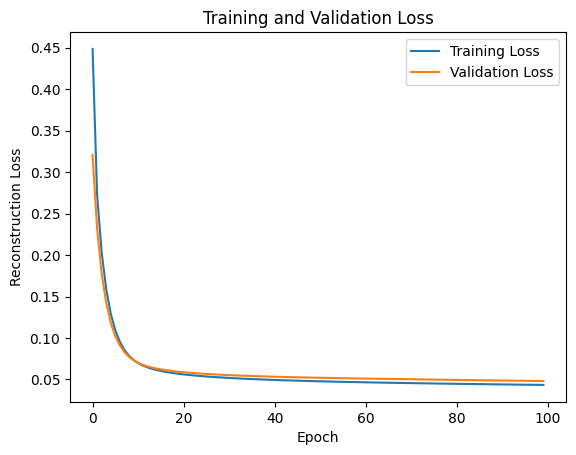

In [101]:
import matplotlib.pyplot as plt

plt.plot(history_ae.history['loss'], label='Training Loss')
plt.plot(history_ae.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Reconstruction Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

## Hyperparameter Grid

In [109]:
learning_rates = [0.001, 0.01, 0.1]
batch_sizes = [16, 32, 64]
epochs_list = [50, 100, 150]

## Logistic Regression

In [8]:
def build_logistic_model(learning_rate):

    model = models.Sequential([
        layers.Input(shape=(X_train_compressed.shape[1],)),
        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model


## Grid Search

In [10]:
def evaluate_model(model, X, y):
    y_prob = model.predict(X, verbose=0)
    y_pred = (y_prob >= 0.5).astype(int).flatten()
    results = {
        'Accuracy': accuracy_score(y, y_pred),
        'Precision': precision_score(y, y_pred, zero_division=0),
        'Recall': recall_score(y, y_pred, zero_division=0),
        'F1-score': f1_score(y, y_pred, zero_division=0),
        'F2-score': fbeta_score(y, y_pred, beta=2),
    }

    return results

In [112]:
grid_results = []
for lr in learning_rates:
    for batch in batch_sizes:
        for epoch in epochs_list:

            # Reset model state and random seed
            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(42)

            # Build a new model
            model = build_logistic_model(lr)

            # Train the model
            model.fit(
                X_train_compressed,
                y_train,
                batch_size=batch,
                epochs=epoch,
                verbose=0
            )

            # Evaluate using validation set
            results = evaluate_model(
                model,
                X_val_compressed,
                y_val
            )

            # Record hyperparameters
            results['Learning Rate'] = lr
            results['Batch Size'] = batch
            results['Epochs'] = epoch

            # Store the results
            grid_results.append(results)

            print(
                f"LR: {lr}, Batch: {batch}, "
                f"Epochs: {epoch}, "
                f"F2-score: {results['F2-score']:.4f}"
            )


LR: 0.001, Batch: 16, Epochs: 50, F2-score: 0.9118
LR: 0.001, Batch: 16, Epochs: 100, F2-score: 0.9096
LR: 0.001, Batch: 16, Epochs: 150, F2-score: 0.9096
LR: 0.001, Batch: 32, Epochs: 50, F2-score: 0.9179
LR: 0.001, Batch: 32, Epochs: 100, F2-score: 0.9184
LR: 0.001, Batch: 32, Epochs: 150, F2-score: 0.9187
LR: 0.001, Batch: 64, Epochs: 50, F2-score: 0.9111
LR: 0.001, Batch: 64, Epochs: 100, F2-score: 0.9110
LR: 0.001, Batch: 64, Epochs: 150, F2-score: 0.9121
LR: 0.01, Batch: 16, Epochs: 50, F2-score: 0.8772
LR: 0.01, Batch: 16, Epochs: 100, F2-score: 0.8772
LR: 0.01, Batch: 16, Epochs: 150, F2-score: 0.8772
LR: 0.01, Batch: 32, Epochs: 50, F2-score: 0.8549
LR: 0.01, Batch: 32, Epochs: 100, F2-score: 0.8549
LR: 0.01, Batch: 32, Epochs: 150, F2-score: 0.8549
LR: 0.01, Batch: 64, Epochs: 50, F2-score: 0.9047
LR: 0.01, Batch: 64, Epochs: 100, F2-score: 0.9047
LR: 0.01, Batch: 64, Epochs: 150, F2-score: 0.9047
LR: 0.1, Batch: 16, Epochs: 50, F2-score: 0.9240
LR: 0.1, Batch: 16, Epochs: 10

## Display Results

In [113]:
df_results = pd.DataFrame(grid_results)

df_results = df_results.sort_values(
    by='F2-score',
    ascending=False
).reset_index(drop=True)

display(df_results)

,Accuracy,Precision,Recall,F1-score,F2-score,Learning Rate,Batch Size,Epochs
0,0.931242,0.902724,0.946939,0.924303,0.937753,0.100,16,100
1,0.938480,0.935351,0.925170,0.930233,0.927188,0.100,16,150
2,0.939083,0.941504,0.919728,0.930489,0.924002,0.100,16,50
3,0.936671,0.942416,0.912925,0.927436,0.918675,0.001,32,150
4,0.936068,0.941094,0.912925,0.926796,0.918423,0.001,32,100
5,0.934861,0.938462,0.912925,0.925517,0.917921,0.001,32,50
6,0.935464,0.948571,0.903401,0.925436,0.912088,0.001,64,150
7,0.934861,0.947218,0.903401,0.924791,0.911837,0.001,16,50
8,0.933052,0.943182,0.903401,0.922863,0.911087,0.001,64,50
9,0.934861,0.948498,0.902041,0.924686,0.910965,0.001,64,100


## Train Final Model

In [11]:
seeds = [42, 123, 456, 789, 1024]
final_results = []

# Optimized hyperparameters
shape = X_train_encoded.shape[1:]
latent_dim = 32
learning_rate = 0.100
epochs = 100
batch_size = 16

for seed in seeds:

    print(f"Training with seed: {seed}")

    # Reset model state and set random seed
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    # Build Autoencoder
    autoencoder = Autoencoder(latent_dim, shape)

    autoencoder.compile(
        optimizer='adam',
        loss=losses.binary_crossentropy
    )

    # Train Autoencoder
    history_ae = autoencoder.fit(
        X_train_encoded,
        X_train_encoded,
        epochs=100,
        shuffle=True,
        validation_data=(X_val_encoded, X_val_encoded),
        verbose=0
    )

    # Extract latent features
    X_train_compressed = autoencoder.encoder.predict(
        X_train_encoded, verbose=0
    )

    X_test_compressed = autoencoder.encoder.predict(
        X_test_encoded, verbose=0
    )

    # Reset random seed before building classifier
    tf.keras.utils.set_random_seed(seed)

    # Build Logistic Regression
    final_logistic_model = build_logistic_model(
        learning_rate=learning_rate
    )

    # Train Logistic Regression
    history = final_logistic_model.fit(
        X_train_compressed,
        y_train,
        epochs=epochs,
        batch_size=batch_size,
        verbose=0
    )

    # Evaluate the model
    results = evaluate_model(
        final_logistic_model,
        X_test_compressed,
        y_test
    )

    # Record evaluation results
    results['Seed'] = seed
    final_results.append(results)

# Convert results into a DataFrame
final_results_df = pd.DataFrame(final_results)

display(final_results_df)

Training with seed: 42
Training with seed: 123
Training with seed: 456
Training with seed: 789
Training with seed: 1024


,Accuracy,Precision,Recall,F1-score,F2-score,Seed
0,0.927667,0.972350,0.861224,0.913420,0.881370,42
1,0.931887,0.890704,0.964626,0.926192,0.948876,123
2,0.899940,0.983022,0.787755,0.874622,0.820346,456
3,0.923448,0.976489,0.847619,0.907502,0.870598,789
4,0.939120,0.931880,0.930612,0.931246,0.930866,1024


In [12]:
summary_df = final_results_df.drop(columns=['Seed']).agg(
    ['mean', 'std']
).T

display(summary_df)

,mean,std
Accuracy,0.924412,0.014854
Precision,0.950889,0.039154
Recall,0.878367,0.070036
F1-score,0.910596,0.022256
F2-score,0.890411,0.051084
